# 07 – SQ3: prestige clusters (K-means) and a price model (OLS regression)

**Requirements:** modeling (regression), model evaluation, correct interpretation · **Extra point:** K-means clustering in addition to the regression · **Data:** table `resorts` in `db/sci_alpi.db`

**Question (SQ3).** Which day-pass price differences are associated with the *size and prestige* of a ski area, once the *national price level* is taken into account, and does a group of "premium" areas exist that is more expensive than its size explains? The comparison between countries is part of the question; it is not only a prediction task.

**Method in three steps**

1. **K-means** groups the ski areas by size and prestige only. The price, the snow and the country are **not** used, otherwise the groups would be built from the thing we want to explain.
2. **OLS regression** of the logarithm of the price relative to the national price level: `y = ln(price / (PLI/100))`, PLI of 2024, EU27 = 100. The groups from step 1, the base elevation and the distance to the nearest feeder city are the predictors.
3. **Evaluation** with R², adjusted R², RMSE in sample and in **5-fold cross-validation** (the model is tested on resorts it has not seen), residual diagnostics and robust standard errors.

All results are *associations at one point in time* (cross-sectional design): "a premium group is associated with a price 20 % higher" never means "the group causes the price".

> **PROVISIONAL.** The size features slope length, number of lifts and the 4–5 star hotels are **not verified yet** (see `data/processed/data_status.json`). The code includes them automatically as soon as they are verified (after `python src/reparse_skiresort.py` and `python src/fetch_hotels_overpass.py` and a re-run of notebooks 02.4 and 05). Until then, size is measured with the **vertical drop** (top minus base elevation), which is verified. A snow-risk variable is not in the model either, because there is no validated snow table for all resorts. The texts that begin with "Automatic reading" are written by the code from the current numbers, so they stay correct after a re-run.

In [1]:
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "db" / "sci_alpi.db"
FIG_DIR = ROOT / "docs" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DB_PATH.exists(), "Run notebook 05_sqlite_database.ipynb first (it creates db/sci_alpi.db)."

SEED = 42                      # every random step uses this seed, so a re-run gives the same numbers
con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
resorts = pd.read_sql_query("SELECT * FROM resorts", con)
pli = pd.read_sql_query("SELECT country, pli_eu27 FROM country_stats WHERE year = 2024", con).set_index("country")["pli_eu27"]
has_snow_table = con.execute("SELECT COUNT(*) FROM sqlite_master WHERE name = 'snow_risk_resorts'").fetchone()[0] == 1
snow_risk = pd.read_sql_query("SELECT * FROM snow_risk_resorts", con) if has_snow_table else None
con.close()

status = json.loads((ROOT / "data" / "processed" / "data_status.json").read_text())
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e3e2de"
COUNTRY_COLOR = {"CH": "#D55E00", "AT": "#0072B2", "FR": "#009E73", "IT": "#CC79A7"}
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
                     "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID})
print("Status of the data:", status)

Status of the data: {'slope_status': ['reparsed', 'unverified_old_parser'], 'hotels_status': ['openstreetmap_overpass']}


## 1. Data for the model

The model uses the **Alpine analysis set** (269 areas: the 275 candidates of the snow roster without six areas that are outside the Alps by geography, see notebook 02.4). The question is about the Alps, and the Pyrenees, Massif Central and Apennines resorts would distort the distance variables (they are 500 to 880 km from any feeder city). Section 5 repeats the model with all 293 areas.

Cross-border areas (5) are counted once, in the country of their main access. Each area has one price, so the rows are independent *as far as the data show*; areas in the same valley share prices and weather, which is a limit (see section 6).

In [2]:
df = resorts[resorts["in_alpine_analysis_set"] == 1].copy().reset_index(drop=True)
df["vertical_drop_m"] = df["elevation_top_m"] - df["elevation_base_m"]
df["pli_2024"] = df["country"].map(pli)
df["price_relative"] = df["price_day_eur"] / (df["pli_2024"] / 100)       # price in "EU27 price level" euros
df["y"] = np.log(df["price_relative"])                                   # outcome of the regression
df["log_dist_nearest_city"] = np.log(df["dist_nearest_city_km"])
df["base_elev_100m"] = df["elevation_base_m"] / 100

# Optional: snow risk, only if a validated table for all resorts exists in the database
if snow_risk is not None and "lost_snow_days" in snow_risk.columns:
    df = df.merge(snow_risk[["resort_id", "lost_snow_days"]], on="resort_id", how="left", validate="1:1")
    print("Snow-risk variable found for", int(df["lost_snow_days"].notna().sum()), "areas.")
else:
    print("No validated snow-risk table in the database: the climate variable is not in the model.")

print(len(df), "areas in the model;", df["country"].value_counts().to_dict())
df[["price_day_eur", "pli_2024", "price_relative", "y"]].describe().round(2)

No validated snow-risk table in the database: the climate variable is not in the model.
269 areas in the model; {'AT': 74, 'CH': 73, 'IT': 69, 'FR': 53}


,price_day_eur,pli_2024,price_relative,y
count,269.00,269.00,269.00,269.00
mean,65.54,129.37,52.80,3.92
std,15.82,34.51,14.80,0.30
min,24.00,98.10,22.22,3.10
25%,56.70,98.10,39.76,3.68
50%,68.25,119.70,53.55,3.98
75%,75.50,184.30,64.22,4.16
max,121.80,184.30,90.72,4.51


## 2. K-means: groups by size and prestige

**What K-means does.** It places *k* centres in the data and assigns every area to the nearest centre, then moves the centres and repeats until nothing changes. Because distance is used, all variables are **standardized** first (mean 0, standard deviation 1); otherwise the elevation in metres would count much more than the rating in stars.

**Features:** top elevation, vertical drop and rating (always); slope length, number of lifts and 4–5 star hotels (only when verified). **Not used:** price, snow, country, position.

**Choosing k.** For k = 2 to 6 the **silhouette score** (from −1 to 1; higher = better separated groups) is computed. The best k is taken from this score, but the groups must also be large enough to be useful (at least 15 areas each).

In [3]:
feature_names = ["elevation_top_m", "vertical_drop_m", "rating_stars"]
excluded = []
df.loc[df["slope_status"] != "reparsed", "slope_km"] = np.nan   # an unverified slope length is never used
if (df["slope_status"] == "reparsed").mean() >= 0.95:
    feature_names.append("slope_km")
else:
    excluded.append("slope_km (not verified)")
if df["lifts_count"].notna().sum() >= 0.9 * len(df):
    feature_names.append("lifts_count")
else:
    excluded.append("lifts_count (empty)")
if (df["hotels_status"] == "openstreetmap_overpass").all():
    feature_names.append("hotels_4_5_star_10km")
else:
    excluded.append("hotels_4_5_star_10km (not measured)")

assert not any(name in feature_names for name in ["price_day_eur", "price_relative", "y", "lost_snow_days", "country"])
# An area without a verified value for a feature cannot be placed in the groups: it is left out and named, never filled in.
incomplete = df[df[feature_names].isna().any(axis=1)]
LEFT_OUT = incomplete["resort_id"].tolist()
if LEFT_OUT:
    print("Left out of K-means and regression because a feature is missing (not verified):", LEFT_OUT)
    df = df.drop(incomplete.index).reset_index(drop=True)
print("Features used for K-means:", feature_names)
print("Excluded until verified:  ", excluded if excluded else "none")

X = df[feature_names].astype(float)
Z = StandardScaler().fit_transform(X)

rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_), "inertia": km.inertia_, "smallest_group": int(np.bincount(km.labels_).min())})
k_table = pd.DataFrame(rows)
k_table.round(3)

Left out of K-means and regression because a feature is missing (not verified): ['aiguille-du-midi-chamonix']
Features used for K-means: ['elevation_top_m', 'vertical_drop_m', 'rating_stars', 'slope_km', 'lifts_count', 'hotels_4_5_star_10km']
Excluded until verified:   none


,k,silhouette,inertia,smallest_group
0,2,0.391,1082.927,67
1,3,0.242,883.734,29
2,4,0.243,752.723,32
3,5,0.240,663.004,13
4,6,0.245,591.689,2


In [4]:
eligible = k_table[k_table["smallest_group"] >= 15]
K = int(eligible.loc[eligible["silhouette"].idxmax(), "k"])
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Z)

# Name the groups by their average standardized score: 1 = smallest / least prestigious, K = largest / most prestigious
score = pd.Series(Z.mean(axis=1), index=df.index)
order = score.groupby(km.labels_).mean().sort_values().index.tolist()
rank_of = {old: new + 1 for new, old in enumerate(order)}
df["cluster"] = pd.Series(km.labels_).map(rank_of).to_numpy()

# Stability: do 20 other random starts find the same groups? (adjusted Rand index: 1 = identical)
ari = [adjusted_rand_score(df["cluster"], KMeans(n_clusters=K, n_init=1, random_state=s).fit(Z).labels_) for s in range(100, 120)]
print(f"Chosen k = {K} (silhouette {silhouette_score(Z, km.labels_):.3f}); stability over 20 random starts: ARI mean {np.mean(ari):.2f}, min {np.min(ari):.2f}")

profile = df.groupby("cluster").agg(n=("resort_id", "size"), **{f: (f, "mean") for f in feature_names}).round(1)
profile["countries"] = df.groupby("cluster")["country"].agg(lambda s: ", ".join(f"{c} {n}" for c, n in s.value_counts().items()))
profile

Chosen k = 2 (silhouette 0.391); stability over 20 random starts: ARI mean 0.86, min 0.01


,n,elevation_top_m,vertical_drop_m,rating_stars,slope_km,lifts_count,hotels_4_5_star_10km,countries
cluster,,,,,,,,
1,201,2306.1,1054.0,3.7,46.6,11.6,4.2,"CH 59, IT 54, AT 53, FR 35"
2,67,2752.9,1572.2,4.3,170.0,44.6,12.0,"AT 21, FR 17, IT 15, CH 14"


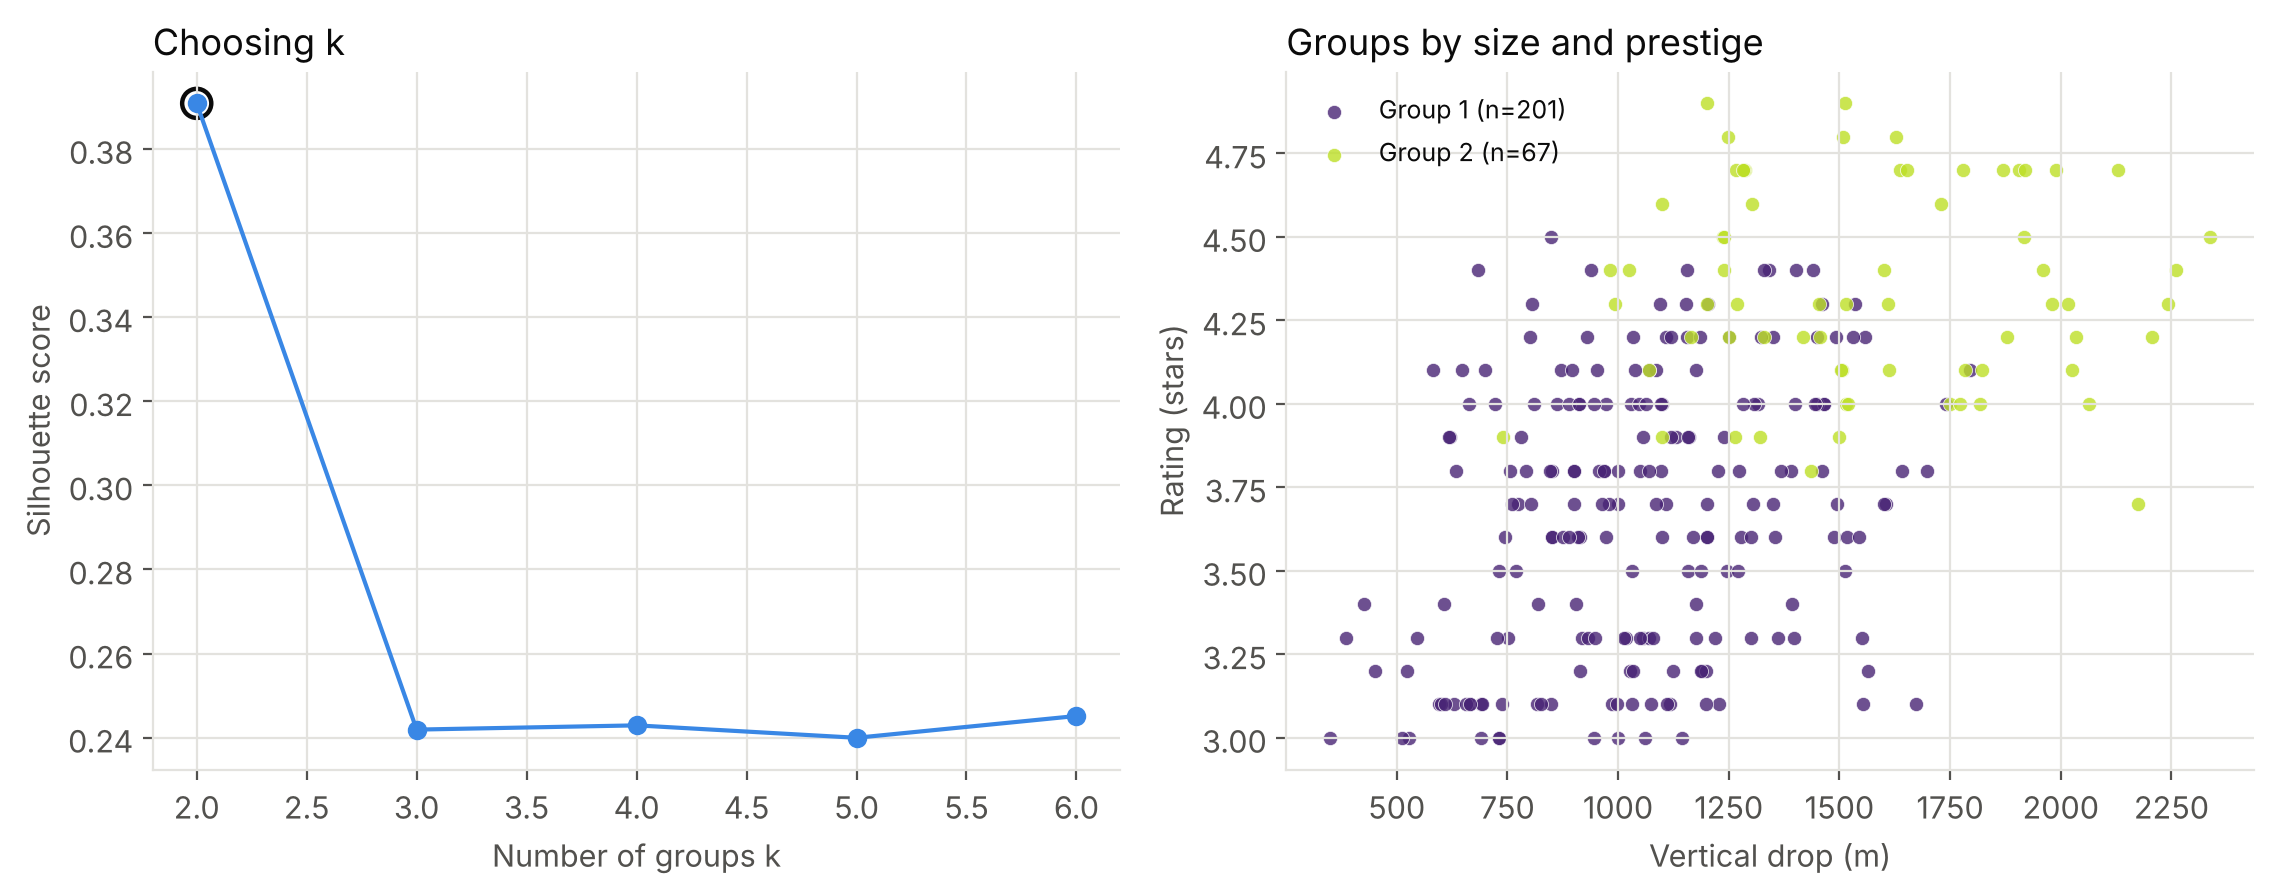

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
ax.plot(k_table["k"], k_table["silhouette"], marker="o", color="#3987e5")
ax.scatter([K], [k_table.loc[k_table["k"] == K, "silhouette"].iloc[0]], s=110, facecolors="none", edgecolors=INK, linewidth=1.6)
ax.set_xlabel("Number of groups k"); ax.set_ylabel("Silhouette score")
ax.set_title("Choosing k", loc="left", fontsize=13, color=INK)

ax = axes[1]
palette = plt.cm.viridis(np.linspace(0.1, 0.9, K))
for c in range(1, K + 1):
    m = df["cluster"] == c
    ax.scatter(df.loc[m, "vertical_drop_m"], df.loc[m, "rating_stars"], s=26, color=palette[c - 1], alpha=0.8, edgecolor="white", linewidth=0.3, label=f"Group {c} (n={int(m.sum())})")
ax.set_xlabel("Vertical drop (m)"); ax.set_ylabel("Rating (stars)")
ax.set_title("Groups by size and prestige", loc="left", fontsize=13, color=INK)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "sq3_kmeans_groups.png", dpi=150, bbox_inches="tight")
plt.show()

**Do the groups differ in price?** The price was **not** used to build the groups, so a price difference between them is a finding and not a circular result. The Kruskal–Wallis test (rank-based, does not need normal data; H0: same price distribution in all groups) and the price per group:

In [6]:
by_cluster = df.groupby("cluster").agg(n=("resort_id", "size"), mean_price_eur=("price_day_eur", "mean"),
                                       median_price_eur=("price_day_eur", "median"), mean_relative_price=("price_relative", "mean")).round(1)
H, p_kw = stats.kruskal(*[g["price_day_eur"].to_numpy() for _, g in df.groupby("cluster")])
print(f"Kruskal-Wallis across the {K} groups: H = {H:.1f}, p = {p_kw:.2g}")
by_cluster

Kruskal-Wallis across the 2 groups: H = 35.3, p = 2.8e-09


,n,mean_price_eur,median_price_eur,mean_relative_price
cluster,,,,
1,201,62.2,65.0,49.6
2,67,75.4,76.0,62.2


## 3. OLS regression

**Reading the model.** The outcome is a logarithm, so a coefficient *b* means that the price changes by about `exp(b) − 1` in percent when the predictor goes up by one unit. The groups are **dummy variables**: group 1 (smallest, least prestigious) is the reference, so the coefficient of group 3 is the price difference between group 3 and group 1 with the other predictors held equal. Standard errors are **robust (HC3)**, which stay valid when the spread of the errors is not constant.

Four specifications are compared:

| Model | Predictors | Question |
|---|---|---|
| M0 | none (mean only) | baseline: how well can one guess without any information? |
| M1 | country | do countries still differ *after* the price level (PLI) has been removed? |
| M2 | size/prestige group, base elevation, distance to nearest feeder city | **planned model (SQ3)** |
| M3 | M2 + country | does a country effect remain beyond price level and prestige? |

In [7]:
def design(data, include_country):
    X = pd.DataFrame(index=data.index)
    for c in sorted(data["cluster"].unique())[1:]:                      # group 1 is the reference
        X[f"group_{c}"] = (data["cluster"] == c).astype(float)
    X["base_elev_100m"] = data["base_elev_100m"]
    X["log_dist_nearest_city"] = data["log_dist_nearest_city"]
    if "lost_snow_days" in data.columns and data["lost_snow_days"].notna().all():
        X["lost_snow_days"] = data["lost_snow_days"]
    if include_country:
        for c in ["AT", "FR", "IT"]:                                    # CH is the reference
            X[f"country_{c}"] = (data["country"] == c).astype(float)
    return X

def country_only(data):
    return pd.DataFrame({f"country_{c}": (data["country"] == c).astype(float) for c in ["AT", "FR", "IT"]}, index=data.index)

SPECS = {
    "M0 baseline (mean only)": lambda d: pd.DataFrame(index=d.index),
    "M1 country":              country_only,
    "M2 group + elevation + distance (planned)": lambda d: design(d, False),
    "M3 M2 + country":         lambda d: design(d, True),
}

def cv_rmse_eur(data, X, y, pli_factor, n_splits=5):
    """5-fold cross-validation. Predictions are converted back to euros so that all models are compared on the same scale."""
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    pred_log = np.zeros(len(y))
    for train, test in kf.split(X if X.shape[1] else data):
        if X.shape[1] == 0:
            pred_log[test] = y.iloc[train].mean()
        else:
            pred_log[test] = LinearRegression().fit(X.iloc[train], y.iloc[train]).predict(X.iloc[test])
    err_log = y.to_numpy() - pred_log
    err_eur = data["price_day_eur"].to_numpy() - np.exp(pred_log) * pli_factor
    return np.sqrt(np.mean(err_log ** 2)), np.sqrt(np.mean(err_eur ** 2))

def evaluate(data):
    pli_factor = (data["pli_2024"] / 100).to_numpy()
    rows, fits = [], {}
    for name, make in SPECS.items():
        X = make(data)
        fit = sm.OLS(data["y"], sm.add_constant(X, has_constant="add") if X.shape[1] else np.ones(len(data))).fit(cov_type="HC3")
        cv_log, cv_eur = cv_rmse_eur(data, X, data["y"], pli_factor)
        resid_eur = data["price_day_eur"].to_numpy() - np.exp(fit.fittedvalues.to_numpy()) * pli_factor
        rows.append({"model": name, "n_predictors": X.shape[1], "R2": fit.rsquared, "adj_R2": fit.rsquared_adj,
                     "RMSE_log_in_sample": np.sqrt(np.mean(fit.resid ** 2)), "RMSE_log_5fold": cv_log,
                     "RMSE_EUR_in_sample": np.sqrt(np.mean(resid_eur ** 2)), "RMSE_EUR_5fold": cv_eur, "AIC": fit.aic})
        fits[name] = (fit, X)
    return pd.DataFrame(rows), fits

comparison, fits = evaluate(df)
comparison.round(3)

,model,n_predictors,R2,adj_R2,RMSE_log_in_sample,RMSE_log_5fold,RMSE_EUR_in_sample,RMSE_EUR_5fold,AIC
0,M0 baseline (mean only),0,-0.000,-0.000,0.298,0.299,19.222,19.240,113.589
1,M1 country,3,0.444,0.437,0.222,0.227,13.359,13.576,-37.611
2,M2 group + elevation + distance (planned),3,0.356,0.349,0.239,0.241,15.150,15.273,1.678
3,M3 M2 + country,6,0.580,0.571,0.193,0.198,11.603,11.887,-107.088


In [8]:
main_name = "M2 group + elevation + distance (planned)"
fit, X_main = fits[main_name]
ci = fit.conf_int()
coef = pd.DataFrame({"coef_log": fit.params, "robust_se": fit.bse, "t": fit.tvalues, "p_value": fit.pvalues,
                     "ci95_low": ci[0], "ci95_high": ci[1]})
coef["effect_pct"] = (np.exp(coef["coef_log"]) - 1) * 100
coef["effect_pct_ci_low"] = (np.exp(coef["ci95_low"]) - 1) * 100
coef["effect_pct_ci_high"] = (np.exp(coef["ci95_high"]) - 1) * 100
coef.loc["const", ["effect_pct", "effect_pct_ci_low", "effect_pct_ci_high"]] = np.nan
coef.round(3)

,coef_log,robust_se,t,p_value,ci95_low,ci95_high,effect_pct,effect_pct_ci_low,effect_pct_ci_high
const,2.441,0.176,13.848,0.000,2.096,2.787,NaN,NaN,NaN
group_2,0.243,0.030,8.058,0.000,0.184,0.303,27.548,20.218,35.324
base_elev_100m,-0.017,0.005,-3.310,0.001,-0.027,-0.007,-1.708,-2.705,-0.700
log_dist_nearest_city,0.347,0.035,10.062,0.000,0.280,0.415,41.525,32.267,51.432


In [9]:
# Same for M3 (country added): which country differences remain?
fit3, X3 = fits["M3 M2 + country"]
ci3 = fit3.conf_int()
coef3 = pd.DataFrame({"coef_log": fit3.params, "robust_se": fit3.bse, "p_value": fit3.pvalues, "ci95_low": ci3[0], "ci95_high": ci3[1]})
coef3["effect_pct"] = (np.exp(coef3["coef_log"]) - 1) * 100
coef3.loc["const", "effect_pct"] = np.nan
coef3.round(3)

,coef_log,robust_se,p_value,ci95_low,ci95_high,effect_pct
const,3.147,0.185,0.000,2.785,3.510,NaN
group_2,0.232,0.025,0.000,0.184,0.281,26.171
base_elev_100m,-0.009,0.004,0.031,-0.017,-0.001,-0.861
log_dist_nearest_city,0.126,0.042,0.003,0.044,0.208,13.460
country_AT,0.356,0.035,0.000,0.287,0.424,42.718
country_FR,0.147,0.041,0.000,0.068,0.227,15.850
country_IT,0.402,0.043,0.000,0.318,0.486,49.539


## 4. Diagnostics: is the model trustworthy?

- **Residuals against fitted values:** should look like a shapeless cloud (no curve, no funnel).
- **QQ plot:** the residuals should follow the line if they are roughly normal (needed for small-sample p-values, less important with about 270 areas).
- **Variance inflation factor (VIF):** shows whether predictors repeat each other; values above 5 to 10 are a warning.
- **Breusch–Pagan test:** H0 = constant spread of the errors. A rejection is the reason why robust standard errors are used.
- **Cook's distance:** which areas have the largest influence on the fitted line.

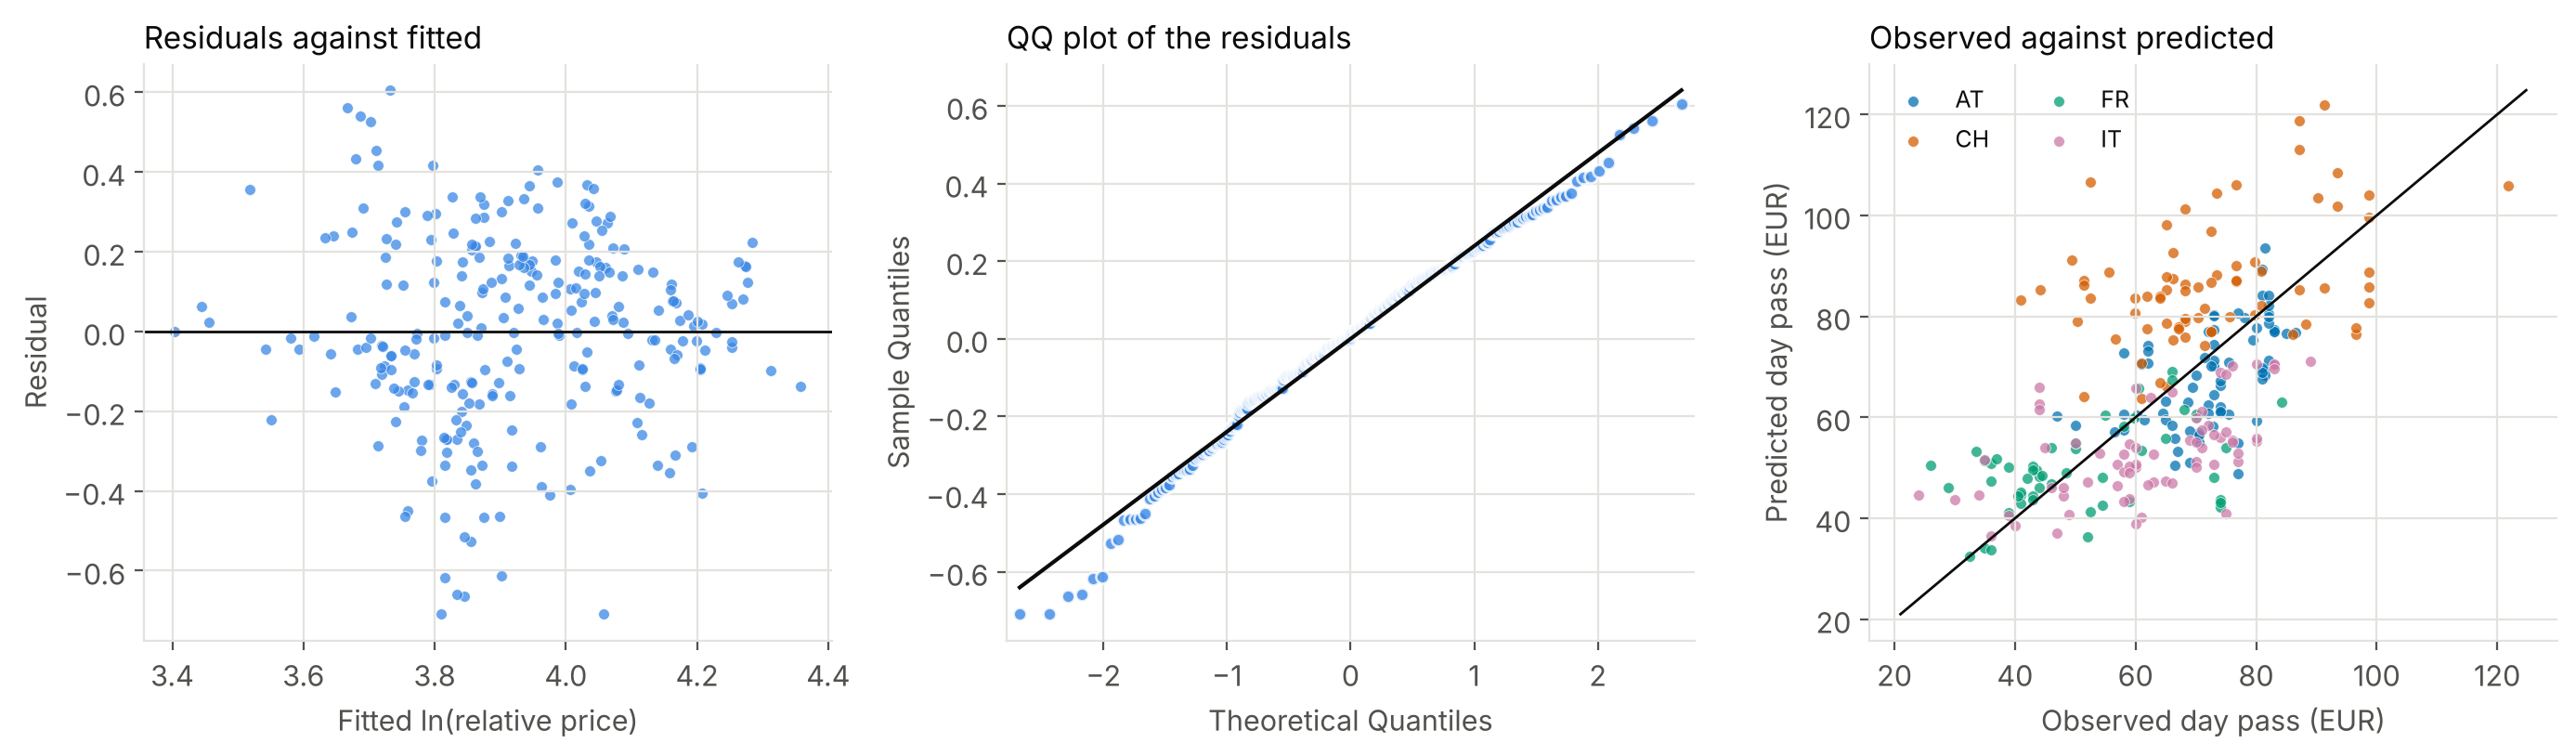

VIF: {'group_2': 1.01, 'base_elev_100m': 1.03, 'log_dist_nearest_city': 1.02}
Breusch-Pagan: LM = 13.5, p = 0.00359
Shapiro-Wilk of the residuals: W = 0.988, p = 0.0209
Largest Cook's distances (threshold 4/n = 0.015):


resort_name
Pitztal Glacier (Pitztaler Gletscher)                                      0.071
Passo dello Stelvio (Stelvio Pass)                                         0.067
Minschuns – Val Müstair-Tschierv                                           0.060
St. Moritz – Corviglia                                                     0.059
Les Portes du Soleil – Morzine/Avoriaz/Les Gets/Châtel/Morgins/Champéry    0.031
dtype: float64

In [10]:
resid, fitted = fit.resid, fit.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].scatter(fitted, resid, s=18, color="#3987e5", alpha=0.75, edgecolor="white", linewidth=0.3)
axes[0].axhline(0, color=INK, linewidth=1)
axes[0].set_xlabel("Fitted ln(relative price)"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals against fitted", loc="left", fontsize=12, color=INK)
sm.qqplot(resid, line="s", ax=axes[1], markerfacecolor="#3987e5", markeredgecolor="white", markersize=5, alpha=0.8)
axes[1].set_title("QQ plot of the residuals", loc="left", fontsize=12, color=INK)
axes[1].get_lines()[1].set_color(INK)
for c, g in df.assign(resid=resid).groupby("country"):
    axes[2].scatter(g["price_day_eur"], np.exp(fitted.loc[g.index]) * (g["pli_2024"] / 100), s=18, color=COUNTRY_COLOR[c], alpha=0.75, edgecolor="white", linewidth=0.3, label=c)
lim = [df["price_day_eur"].min() - 3, df["price_day_eur"].max() + 3]
axes[2].plot(lim, lim, color=INK, linewidth=1)
axes[2].set_xlabel("Observed day pass (EUR)"); axes[2].set_ylabel("Predicted day pass (EUR)")
axes[2].set_title("Observed against predicted", loc="left", fontsize=12, color=INK)
axes[2].legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "sq3_regression_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

Xc = sm.add_constant(X_main)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X_main.columns).round(2)
bp_stat, bp_p, _, _ = het_breuschpagan(fit.resid, sm.add_constant(X_main))
sw_w, sw_p = stats.shapiro(resid)
influence = sm.OLS(df["y"], sm.add_constant(X_main)).fit().get_influence()      # Cook's distance from the plain OLS fit
cook = pd.Series(influence.cooks_distance[0], index=df["resort_name"]).sort_values(ascending=False)
print("VIF:", vif.to_dict())
print(f"Breusch-Pagan: LM = {bp_stat:.1f}, p = {bp_p:.3g}")
print(f"Shapiro-Wilk of the residuals: W = {sw_w:.3f}, p = {sw_p:.3g}")
print("Largest Cook's distances (threshold 4/n = %.3f):" % (4 / len(df)))
cook.head(5).round(3)

## 5. Robustness checks

(a) The same model on **all 293 areas** (including the Pyrenees, Massif Central, Apennines, Jura and Bohemian Forest areas). (b) **No log**: the outcome is the relative price in euros, to see whether the logarithm matters. (c) **Without the most influential area**. (d) **k = 3 groups** instead of the number chosen by the silhouette score, to see whether the finding depends on k.

In [11]:
rob = []
# (a) all 293 areas
d_all = resorts.copy()
d_all["vertical_drop_m"] = d_all["elevation_top_m"] - d_all["elevation_base_m"]
d_all["pli_2024"] = d_all["country"].map(pli)
d_all["y"] = np.log(d_all["price_day_eur"] / (d_all["pli_2024"] / 100))
d_all["log_dist_nearest_city"] = np.log(d_all["dist_nearest_city_km"])
d_all["base_elev_100m"] = d_all["elevation_base_m"] / 100
d_all = d_all.dropna(subset=feature_names).reset_index(drop=True)   # same rule as the main model: no value is filled in
Za = StandardScaler().fit_transform(d_all[feature_names].astype(float))
d_all["cluster"] = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Za).labels_
rank_all = d_all.assign(s=Za.mean(axis=1)).groupby("cluster")["s"].mean().sort_values().index.tolist()
d_all["cluster"] = d_all["cluster"].map({old: new + 1 for new, old in enumerate(rank_all)})
cmp_all, fits_all = evaluate(d_all)
r_all = cmp_all[cmp_all["model"] == main_name].iloc[0]
rob.append({"check": "(a) all 293 areas", "n": len(d_all), "R2": r_all["R2"], "RMSE_EUR_5fold": r_all["RMSE_EUR_5fold"]})

# (b) no log: relative price in euros as the outcome
Xb = X_main
fit_b = sm.OLS(df["price_relative"], sm.add_constant(Xb)).fit(cov_type="HC3")
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
pred = np.zeros(len(df))
for tr, te in kf.split(Xb):
    pred[te] = LinearRegression().fit(Xb.iloc[tr], df["price_relative"].iloc[tr]).predict(Xb.iloc[te])
rmse_b = np.sqrt(np.mean((df["price_day_eur"] - pred * df["pli_2024"] / 100) ** 2))
rob.append({"check": "(b) no log (level outcome)", "n": len(df), "R2": fit_b.rsquared, "RMSE_EUR_5fold": rmse_b})

# (c) without the most influential area
drop_name = cook.index[0]
d_c = df[df["resort_name"] != drop_name]
cmp_c, _ = evaluate(d_c)
r_c = cmp_c[cmp_c["model"] == main_name].iloc[0]
rob.append({"check": f"(c) without {drop_name[:40]}", "n": len(d_c), "R2": r_c["R2"], "RMSE_EUR_5fold": r_c["RMSE_EUR_5fold"]})

# (d) three groups instead of the silhouette choice
km3 = KMeans(n_clusters=3, n_init=50, random_state=SEED).fit(Z)
order3 = pd.Series(Z.mean(axis=1)).groupby(km3.labels_).mean().sort_values().index.tolist()
d3 = df.copy()
d3["cluster"] = pd.Series(km3.labels_).map({o: i + 1 for i, o in enumerate(order3)}).to_numpy()
cmp3, fits3 = evaluate(d3)
r3 = cmp3[cmp3["model"] == main_name].iloc[0]
rob.append({"check": "(d) k = 3 groups", "n": len(d3), "R2": r3["R2"], "RMSE_EUR_5fold": r3["RMSE_EUR_5fold"]})
price_k3 = d3.groupby("cluster")["price_day_eur"].mean().round(1)
print("k = 3: mean price per group", price_k3.to_dict(), "| silhouette", round(silhouette_score(Z, km3.labels_), 3))

main_row = comparison[comparison["model"] == main_name].iloc[0]
rob.insert(0, {"check": "main model (Alpine analysis set, log)", "n": len(df), "R2": main_row["R2"], "RMSE_EUR_5fold": main_row["RMSE_EUR_5fold"]})
robust = pd.DataFrame(rob)
robust.round(3)

k = 3: mean price per group {1: 57.9, 2: 70.9, 3: 77.4} | silhouette 0.242


,check,n,R2,RMSE_EUR_5fold
0,"main model (Alpine analysis set, log)",268,0.356,15.273
1,(a) all 293 areas,292,0.251,15.966
2,(b) no log (level outcome),268,0.376,15.824
3,(c) without Pitztal Glacier (Pitztaler Gletscher),267,0.364,15.163
4,(d) k = 3 groups,268,0.408,15.003


## 6. Automatic reading of the results

The text below is built from the numbers of this run. It states what the model finds and where it is weak.

In [12]:
from IPython.display import Markdown, display

m0 = comparison.iloc[0]; m1 = comparison.iloc[1]; m2 = comparison.iloc[2]; m3 = comparison.iloc[3]
group_rows = [i for i in coef.index if i.startswith("group_")]
lines = []
lines.append(f"**Groups.** K-means found **{K} groups** by size and prestige (features: {', '.join(feature_names)}); with the best of 50 random starts the solution is the one used here; single random starts agree with it on average (mean ARI {np.mean(ari):.2f}, worst case {np.min(ari):.2f}), so a single start can end in a poorer split and that is why 50 starts are used. "
             f"Their price was not used to build them, yet the average price rises from {by_cluster['mean_price_eur'].iloc[0]:.1f} EUR in group 1 to {by_cluster['mean_price_eur'].iloc[-1]:.1f} EUR in group {K} (Kruskal-Wallis p {'< 0.001' if p_kw < 0.001 else '= ' + format(p_kw, '.3f')}).")
lines.append(f"**Fit.** The planned model M2 explains **{m2['R2']*100:.0f} %** of the variance of the log relative price (adjusted R² {m2['adj_R2']:.2f}). "
             f"In 5-fold cross-validation its prediction error is **{m2['RMSE_EUR_5fold']:.1f} EUR**, against {m0['RMSE_EUR_5fold']:.1f} EUR for guessing the average (M0): "
             f"{(1 - m2['RMSE_EUR_5fold']/m0['RMSE_EUR_5fold'])*100:.0f} % smaller. The gap between the in-sample error ({m2['RMSE_EUR_in_sample']:.1f} EUR) and the cross-validated error is small, so there is no sign of strong overfitting.")
for g in group_rows:
    r = coef.loc[g]
    lines.append(f"- **{g.replace('_', ' ').capitalize()} against group 1:** price {r['effect_pct']:+.0f} % (95 % CI {r['effect_pct_ci_low']:+.0f} % to {r['effect_pct_ci_high']:+.0f} %, p {'< 0.001' if r['p_value'] < 0.001 else '= ' + format(r['p_value'], '.3f')}).")
for name, label in [("base_elev_100m", "Base elevation, per +100 m"), ("log_dist_nearest_city", "Distance to the nearest feeder city, doubled")]:
    r = coef.loc[name]
    eff = (np.exp(r["coef_log"] * (1 if name == "base_elev_100m" else np.log(2))) - 1) * 100
    lines.append(f"- **{label}:** price {eff:+.1f} % (p {'< 0.001' if r['p_value'] < 0.001 else '= ' + format(r['p_value'], '.3f')}).")
lines.append(f"**Country.** Without any prestige information, the country still explains part of the PLI-adjusted price (M1: R² {m1['R2']*100:.0f} %, cross-validated error {m1['RMSE_EUR_5fold']:.1f} EUR). "
             f"Adding the country to the planned model (M3) changes the cross-validated error from {m2['RMSE_EUR_5fold']:.1f} to {m3['RMSE_EUR_5fold']:.1f} EUR; "
             + ", ".join(f"{i.replace('country_', '')} {coef3.loc[i, 'effect_pct']:+.0f} % against CH (p {'< 0.001' if coef3.loc[i, 'p_value'] < 0.001 else '= ' + format(coef3.loc[i, 'p_value'], '.3f')})" for i in coef3.index if i.startswith("country_")) + ".")
g_m2, g_m3 = coef.loc["group_2", "effect_pct"], coef3.loc["group_2", "effect_pct"]
d_m2 = (np.exp(coef.loc["log_dist_nearest_city", "coef_log"] * np.log(2)) - 1) * 100
d_m3 = (np.exp(coef3.loc["log_dist_nearest_city", "coef_log"] * np.log(2)) - 1) * 100
lines.append(f"**Which results are stable?** The size/prestige effect hardly changes when the country is added (group 2: {g_m2:+.0f} % in M2, {g_m3:+.0f} % in M3), so it is not a country effect in disguise. "
             f"The effect of the distance to the nearest feeder city shrinks from {d_m2:+.0f} % to {d_m3:+.0f} % per doubling, so it mostly reflects which countries are far from the cities and should not be read as a remoteness premium.")
price_ratio = df.groupby("country")["price_day_eur"].mean()
pli_ratio = pli
lines.append(f"**The PLI adjustment is not enough to remove the country.** If day passes followed the national price level one to one, the PLI-adjusted prices would be the same in all countries. They are not (M1 explains {m1['R2']*100:.0f} % of their variance): "
             f"a Swiss day pass costs {price_ratio['CH'] / price_ratio['IT']:.2f} times an Italian one, while Swiss prices in general are {pli_ratio['CH'] / pli_ratio['IT']:.2f} times the Italian level. "
             f"Day-pass prices are therefore much less tied to the national price level than the model assumes, and the country dummies in M3 pick up what is left.")
sil = silhouette_score(Z, km.labels_)
lines.append(f"**How real are the groups?** The silhouette score of {sil:.2f} means a weak to moderate structure (above 0.5 would be clear groups). Size and prestige form a continuum, so the groups are a useful split ('large and prestigious' against 'small') and not natural clusters; "
             f"{K + 1} groups have a {'similar' if abs(k_table.loc[k_table['k'] == K + 1, 'silhouette'].iloc[0] - sil) < 0.05 else 'lower' if k_table.loc[k_table['k'] == K + 1, 'silhouette'].iloc[0] < sil else 'higher'} score ({k_table.loc[k_table['k'] == K + 1, 'silhouette'].iloc[0]:.2f}) {'and the same price ordering' if price_k3.is_monotonic_increasing else 'but a different price ordering'} (see the robustness check).")
lines.append(f"**Diagnostics.** Largest VIF {vif.max():.1f}; Breusch-Pagan p {'< 0.001' if bp_p < 0.001 else '= ' + format(bp_p, '.3f')}"
             f"{' (unequal spread, so the robust standard errors are needed)' if bp_p < 0.05 else ''}; residual normality (Shapiro-Wilk) p {'< 0.001' if sw_p < 0.001 else '= ' + format(sw_p, '.3f')}; "
             f"{int((cook > 4 / len(df)).sum())} areas above the Cook's distance threshold, the largest is {cook.index[0]}.")
lines.append(f"**Robustness (R² and cross-validated error).** Main model {robust.loc[0, 'R2']:.2f} and {robust.loc[0, 'RMSE_EUR_5fold']:.1f} EUR; all 293 areas {robust.loc[1, 'R2']:.2f} and {robust.loc[1, 'RMSE_EUR_5fold']:.1f} EUR; without the log {robust.loc[2, 'R2']:.2f} and {robust.loc[2, 'RMSE_EUR_5fold']:.1f} EUR; "
             f"without the most influential area {robust.loc[3, 'R2']:.2f} and {robust.loc[3, 'RMSE_EUR_5fold']:.1f} EUR; three groups instead of {K} {robust.loc[4, 'R2']:.2f} and {robust.loc[4, 'RMSE_EUR_5fold']:.1f} EUR "
             f"(mean price per group {', '.join(f'{v:.1f}' for v in price_k3.values)} EUR, rising with the group).")
lines.append(f"**Status.** {'PROVISIONAL: ' + '; '.join(excluded) + '.' if excluded else 'All size features are verified.'} "
             f"{'Climate risk is not in the model (no validated snow table for all areas).' if 'lost_snow_days' not in X_main.columns else 'Climate risk (lost snow days) is in the model.'}")
display(Markdown("\n\n".join(lines)))

**Groups.** K-means found **2 groups** by size and prestige (features: elevation_top_m, vertical_drop_m, rating_stars, slope_km, lifts_count, hotels_4_5_star_10km); with the best of 50 random starts the solution is the one used here; single random starts agree with it on average (mean ARI 0.86, worst case 0.01), so a single start can end in a poorer split and that is why 50 starts are used. Their price was not used to build them, yet the average price rises from 62.2 EUR in group 1 to 75.4 EUR in group 2 (Kruskal-Wallis p < 0.001).

**Fit.** The planned model M2 explains **36 %** of the variance of the log relative price (adjusted R² 0.35). In 5-fold cross-validation its prediction error is **15.3 EUR**, against 19.2 EUR for guessing the average (M0): 21 % smaller. The gap between the in-sample error (15.1 EUR) and the cross-validated error is small, so there is no sign of strong overfitting.

- **Group 2 against group 1:** price +28 % (95 % CI +20 % to +35 %, p < 0.001).

- **Base elevation, per +100 m:** price -1.7 % (p < 0.001).

- **Distance to the nearest feeder city, doubled:** price +27.2 % (p < 0.001).

**Country.** Without any prestige information, the country still explains part of the PLI-adjusted price (M1: R² 44 %, cross-validated error 13.6 EUR). Adding the country to the planned model (M3) changes the cross-validated error from 15.3 to 11.9 EUR; AT +43 % against CH (p < 0.001), FR +16 % against CH (p < 0.001), IT +50 % against CH (p < 0.001).

**Which results are stable?** The size/prestige effect hardly changes when the country is added (group 2: +28 % in M2, +26 % in M3), so it is not a country effect in disguise. The effect of the distance to the nearest feeder city shrinks from +27 % to +9 % per doubling, so it mostly reflects which countries are far from the cities and should not be read as a remoteness premium.

**The PLI adjustment is not enough to remove the country.** If day passes followed the national price level one to one, the PLI-adjusted prices would be the same in all countries. They are not (M1 explains 44 % of their variance): a Swiss day pass costs 1.18 times an Italian one, while Swiss prices in general are 1.88 times the Italian level. Day-pass prices are therefore much less tied to the national price level than the model assumes, and the country dummies in M3 pick up what is left.

**How real are the groups?** The silhouette score of 0.39 means a weak to moderate structure (above 0.5 would be clear groups). Size and prestige form a continuum, so the groups are a useful split ('large and prestigious' against 'small') and not natural clusters; 3 groups have a lower score (0.24) and the same price ordering (see the robustness check).

**Diagnostics.** Largest VIF 1.0; Breusch-Pagan p = 0.004 (unequal spread, so the robust standard errors are needed); residual normality (Shapiro-Wilk) p = 0.021; 12 areas above the Cook's distance threshold, the largest is Pitztal Glacier (Pitztaler Gletscher).

**Robustness (R² and cross-validated error).** Main model 0.36 and 15.3 EUR; all 293 areas 0.25 and 16.0 EUR; without the log 0.38 and 15.8 EUR; without the most influential area 0.36 and 15.2 EUR; three groups instead of 2 0.41 and 15.0 EUR (mean price per group 57.9, 70.9, 77.4 EUR, rising with the group).

**Status.** All size features are verified. Climate risk is not in the model (no validated snow table for all areas).

**Limits that always apply**

- **Association, not causation.** The data are one price list at one date; the model cannot say what would happen to the price if a resort became bigger or more prestigious.
- **Prestige is partly measured by the rating**, an editorial score that already reflects price and quality, so the group effect partly describes how the website rates expensive resorts.
- **Neighbouring areas are not independent** (shared lift passes, regional pricing, the same weather). The robust standard errors do not remove this; the p-values are therefore *nominal* and somewhat optimistic.
- **One PLI value per country.** The PLI cannot be separated from other differences between countries (wages, regulation, competition); that is why M3 checks what remains.
- **Climate risk** is the key variable of the main research question. It enters this model only when a validated snow table for all resorts exists; until then SQ3 answers "what do size and prestige explain?", not "do prices reflect snow risk?".

## 7. Save the results and check the work

In [13]:
# Results are saved so that the report and the slides use exactly these numbers
results = df[["resort_id", "resort_name", "country", "cluster", "price_day_eur", "price_relative"]].assign(fitted_log=fit.fittedvalues.to_numpy(), residual_log=fit.resid.to_numpy())
results.to_csv(OUT_DIR / "sq3_cluster_and_model_results.csv", index=False)
comparison.to_csv(OUT_DIR / "sq3_model_comparison.csv", index=False)
coef.to_csv(OUT_DIR / "sq3_regression_coefficients.csv")
(OUT_DIR / "sq3_status.json").write_text(json.dumps({"provisional": bool(excluded), "features_used": feature_names, "excluded_not_verified": excluded,
                                                      "n_areas": int(len(df)), "left_out_missing_feature": LEFT_OUT, "k": K, "seed": SEED}, indent=2))

# 1) statsmodels and scikit-learn give the same coefficients (two independent implementations)
sk = LinearRegression().fit(X_main, df["y"])
assert np.allclose(sk.coef_, fit.params.drop("const").to_numpy(), atol=1e-8) and np.isclose(sk.intercept_, fit.params["const"])

# 2) R2 recomputed by hand
ss_res = float(np.sum(fit.resid ** 2)); ss_tot = float(np.sum((df["y"] - df["y"].mean()) ** 2))
assert np.isclose(1 - ss_res / ss_tot, fit.rsquared)

# 3) Groups: every area in exactly one group, sizes add up, no group smaller than 15
assert df["cluster"].between(1, K).all() and int(df["cluster"].value_counts().sum()) == len(df) and df["cluster"].value_counts().min() >= 15

# 4) The price was not used for the clustering, and the group order follows the standardized score
assert "price_day_eur" not in feature_names and "price_relative" not in feature_names
assert pd.Series(Z.mean(axis=1)).groupby(df["cluster"].to_numpy()).mean().is_monotonic_increasing

# 5) Cross-validation: the cross-validated error is never below the in-sample error by construction (up to noise)
assert (comparison["RMSE_log_5fold"] >= comparison["RMSE_log_in_sample"] - 1e-9).all()

# 6) The model beats the baseline in cross-validation
assert comparison.loc[comparison["model"] == main_name, "RMSE_EUR_5fold"].iloc[0] < comparison.loc[0, "RMSE_EUR_5fold"]

# 7) The saved status file agrees with the data status
assert (sorted(resorts["slope_status"].unique()) == status["slope_status"]) and (sorted(resorts["hotels_status"].unique()) == status["hotels_status"])

print("All checks passed.")

All checks passed.
